In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [141]:
dataset = pd.read_csv("../data/raw/city_day.csv")
dataset.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [142]:
dataset.info()


<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


In [143]:
print("Rows:", dataset.shape[0])
print("Columns:", dataset.shape[1])

Rows: 29531
Columns: 16


In [144]:
dataset["Date"] = pd.to_datetime(dataset["Date"])

dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  str           
 1   Date        29531 non-null  datetime64[us]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  str           
dtypes: datetime64[us](1), float64(13)

# DATE to check the range of yrs of data we have

In [145]:
print("Start date:", dataset["Date"].min())
print("End date:", dataset["Date"].max())

Start date: 2015-01-01 00:00:00
End date: 2020-07-01 00:00:00


In [146]:
dataset["Date"].dt.year.value_counts().sort_index()

Date
2015    2801
2016    3478
2017    4689
2018    6471
2019    7446
2020    4646
Name: count, dtype: int64

# Checking No. of observation of each city we have in our data

In [147]:
print("Number of cities:", dataset["City"].nunique())

print("\nCities:")
print(sorted(dataset["City"].dropna().unique()))

print("\nRows per city:")
print(dataset["City"].value_counts())

Number of cities: 26

Cities:
['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']

Rows per city:
City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ernaku

In [148]:
print("Total rows:", len(dataset))
print("AQI available:", dataset["AQI"].notna().sum())
print("AQI missing:", dataset["AQI"].isna().sum())

print("AQI availability by city:")
print(
    dataset.groupby("City")["AQI"]
    .agg(["count", "size"])
    .sort_values("count")
)

Total rows: 29531
AQI available: 24850
AQI missing: 4681
AQI availability by city:
                    count  size
City                           
Aizawl                111   113
Ernakulam             153   162
Kochi                 158   162
Shillong              205   310
Bhopal                278   289
Chandigarh            299   304
Coimbatore            344   386
Guwahati              495   502
Talcher               698   925
Brajrajnagar          713   938
Kolkata               754   814
Jorapokhar            771  1169
Mumbai                775  2009
Amaravati             841   951
Thiruvananthapuram   1052  1112
Jaipur               1094  1114
Amritsar             1126  1221
Visakhapatnam        1171  1462
Ahmedabad            1334  2009
Gurugram             1453  1679
Patna                1459  1858
Hyderabad            1880  2006
Chennai              1884  2009
Lucknow              1893  2009
Bengaluru            1910  2009
Delhi                1999  2009


# Now finding out how much data we have missing

In [149]:
missing = dataset.isnull().sum()

missing_percentage = (missing/len(dataset)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing,
    "Missing %": missing_percentage
})
missing_report.sort_values( "Missing %", ascending=False)

,Missing Values,Missing %
Xylene,18109,61.322001
PM10,11140,37.723071
NH3,10328,34.973418
Toluene,8041,27.229014
Benzene,5623,19.041008
AQI,4681,15.851139
AQI_Bucket,4681,15.851139
PM2.5,4598,15.570079
NOx,4185,14.171549
O3,4022,13.619586


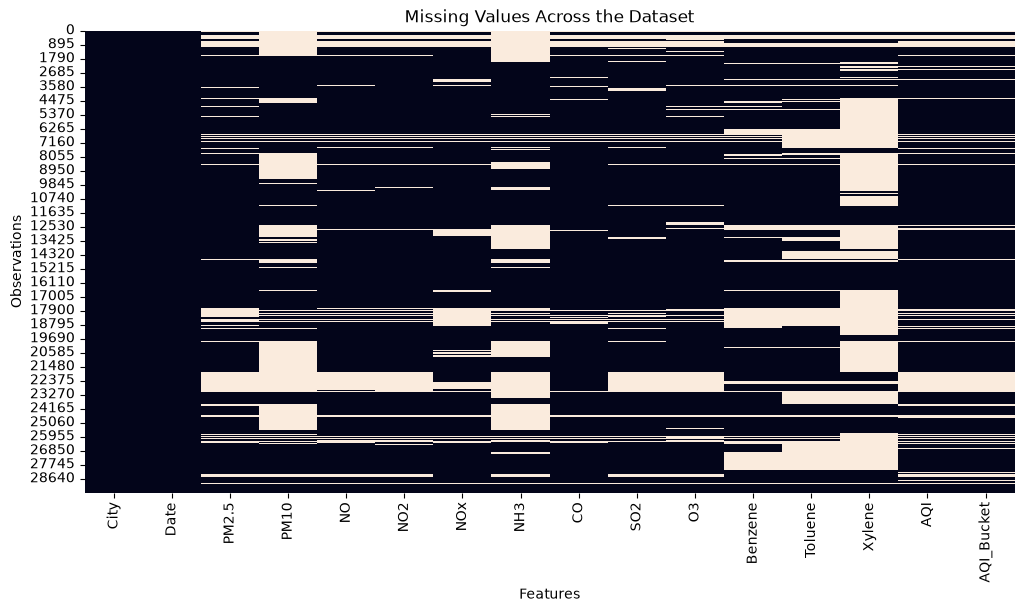

In [150]:
plt.figure(figsize=(12, 6))

sns.heatmap(dataset.isnull(), cbar=False)

plt.title("Missing Values Across the Dataset")
plt.xlabel("Features")
plt.ylabel("Observations")

plt.show()

In [151]:
dataset["AQI"].describe()

count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64

# Checking how our data is distributed

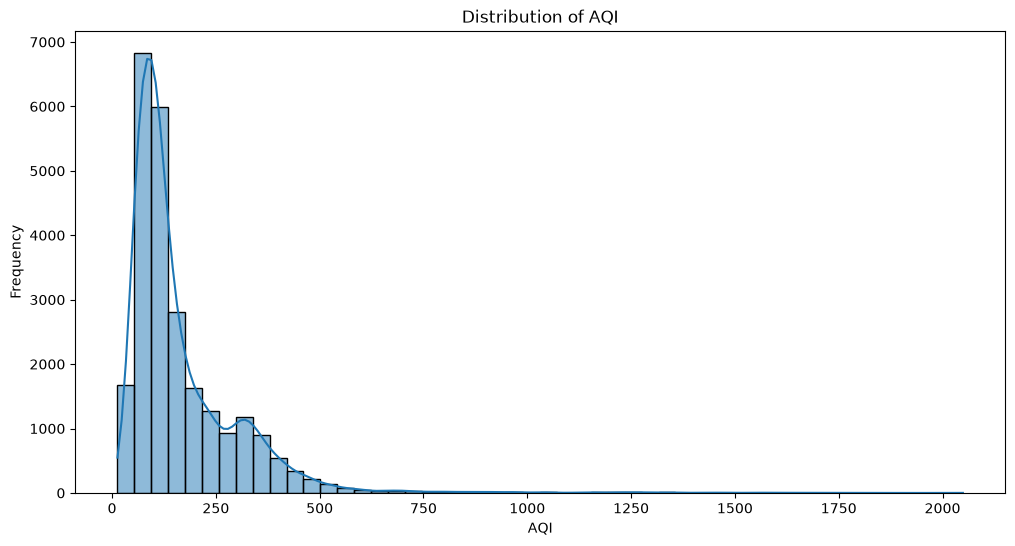

In [152]:
plt.figure(figsize=(12, 6))

sns.histplot(dataset["AQI"].dropna(), bins=50, kde=True)

plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.show()
#Our data is right skewed

#Till now we know that:-
1. Our data is right skewed
2. There are 4681 observations where AQI is missing
3. Some features have highly missing data so we will drop them 


In [153]:
dataset.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


# Decided to drop NH3, NOx ,Benzene, Toulene, Xylene as they have high amount of data missing as we saw in the graph
  # But still we are considering PM 10 because it is an interesting feature for businessess for recommendations


In [154]:
#Planning to remove some features

selected_features = [
    "PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "AQI"
]

dataset[selected_features].isnull().sum()

PM2.5     4598
PM10     11140
NO2       3585
SO2       3854
CO        2059
O3        4022
AQI       4681
dtype: int64

In [155]:
(dataset[selected_features].isnull().mean() * 100).round(2)

PM2.5    15.57
PM10     37.72
NO2      12.14
SO2      13.05
CO        6.97
O3       13.62
AQI      15.85
dtype: float64

In [156]:
dataset[selected_features].dropna().shape



(16010, 7)

# Can't simply delete observations with null values as complete-case deletion is probably too aggressive

In [157]:
dataset.groupby("City")["PM10"].apply(lambda x: x.isnull().mean() * 100).sort_values(ascending=False)

City
Lucknow               100.000000
Patna                  89.720129
Chennai                84.967646
Ahmedabad              79.741165
Mumbai                 62.020906
Gurugram               55.926147
Jorapokhar             23.524380
Shillong               22.258065
Talcher                19.351351
Brajrajnagar           18.443497
Bengaluru              17.919363
Hyderabad              17.696909
Visakhapatnam          16.142271
Kolkata                 6.756757
Amaravati               5.783386
Amritsar                5.159705
Delhi                   3.832753
Thiruvananthapuram      3.417266
Bhopal                  3.114187
Ernakulam               2.469136
Coimbatore              1.813472
Jaipur                  1.256732
Aizawl                  0.884956
Kochi                   0.000000
Chandigarh              0.000000
Guwahati                0.000000
Name: PM10, dtype: float64

In [158]:
city_data = dataset.groupby("City").agg(
    total_observations=("AQI", "size"),
    aqi_available=("AQI", "count"),
    pm10_available=("PM10", "count")
)

city_data["AQI_available_%"] = (
    city_data["aqi_available"] / city_data["total_observations"] * 100
).round(2)

city_data["PM10_available_%"] = (
    city_data["pm10_available"] / city_data["total_observations"] * 100
).round(2)

city_data.sort_values("PM10_available_%")


,total_observations,aqi_available,pm10_available,AQI_available_%,PM10_available_%
City,,,,,
Lucknow,2009,1893,0,94.23,0.00
Patna,1858,1459,191,78.53,10.28
Chennai,2009,1884,302,93.78,15.03
Ahmedabad,2009,1334,407,66.40,20.26
Mumbai,2009,775,763,38.58,37.98
Gurugram,1679,1453,740,86.54,44.07
Jorapokhar,1169,771,894,65.95,76.48
Shillong,310,205,241,66.13,77.74
Talcher,925,698,746,75.46,80.65



# So from here we got to know that we can't simply just fill null PM10 with mean or some sort of artifical data 
# It will be better if we drop that. Even it is only 37% missing if calculated over all observation but the 
# missingness is highly concentrated in some cities like Lucknow so dropping PM10 as feature is best for now

In [159]:
model_features = [
    "PM2.5", "NO2", "SO2", "CO", "O3", "AQI"
]

dataset[model_features].dropna().shape


(22618, 6)

# so we can see we recovered from 16010 to 22618 observations
# EDA done here

In [160]:
model_features = ["PM2.5", "NO2", "SO2", "CO", "O3"]

model_data = dataset[model_features + ["AQI"]].copy()

model_data.shape

(29531, 6)

In [161]:
model_data.isnull().sum()

PM2.5    4598
NO2      3585
SO2      3854
CO       2059
O3       4022
AQI      4681
dtype: int64

In [162]:
dataset.groupby("City")[model_features].apply(
    lambda x: x.isnull().mean() * 100
).round(2)

,PM2.5,NO2,SO2,CO,O3
City,,,,,
Ahmedabad,31.26,30.26,31.86,30.31,34.10
Aizawl,1.77,0.00,0.00,0.00,7.96
Amaravati,6.20,5.78,6.83,10.20,5.78
Amritsar,10.48,3.60,13.76,6.22,9.42
Bengaluru,7.27,0.30,0.30,0.55,7.17
Bhopal,3.11,3.11,3.11,3.11,3.11
Brajrajnagar,19.72,24.95,20.58,15.99,21.64
Chandigarh,4.93,1.32,0.00,0.00,0.00
Chennai,5.82,1.79,1.79,1.24,2.44


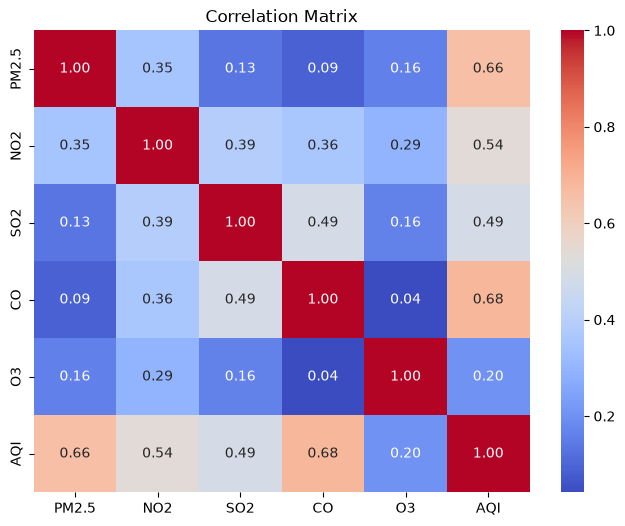

In [163]:
#Checking correlation
plt.figure(figsize=(8, 6))

sns.heatmap(model_data.corr(),annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()
#PM2.5 and CO has high linear relationship with AQI
#NO2 and SO2 moderate
#O3 weak

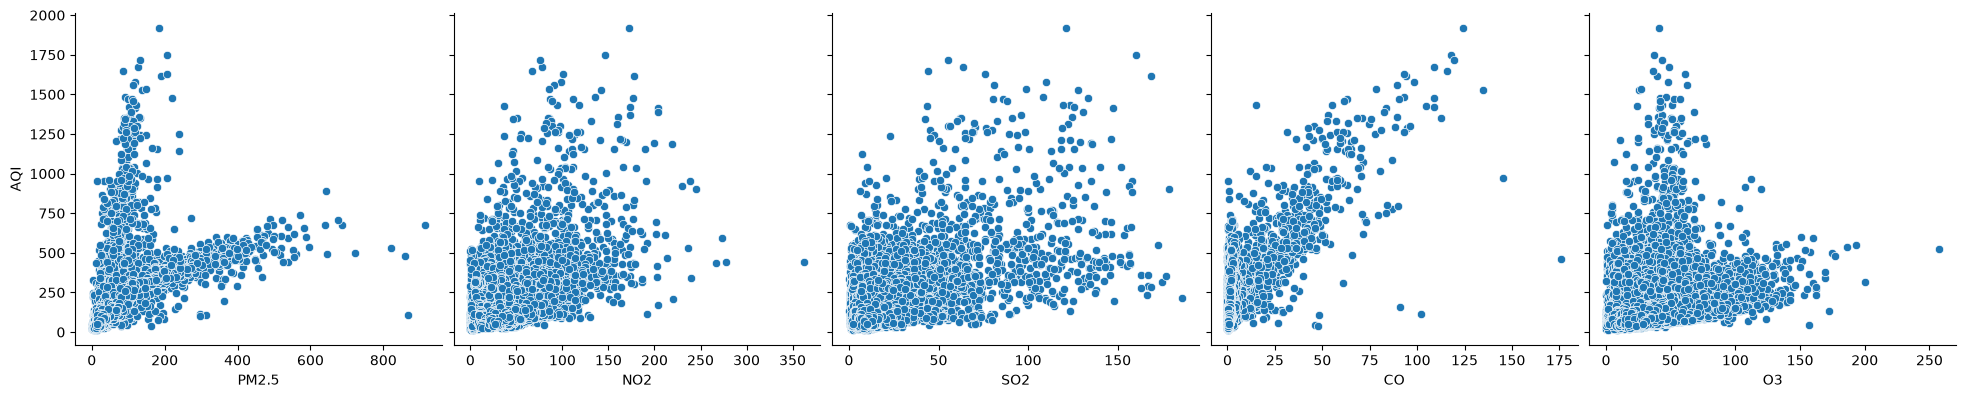

In [164]:
sns.pairplot(
    model_data[model_features + ["AQI"]].dropna(),y_vars=["AQI"],x_vars=model_features,height=4)

plt.show()
# PM2.5 AQI: clear positive relationship, but with considerable spread.
# NO2 AQI: positive relationship, but weaker and more scattered.
# SO2 AQI: positive relationship with noticeable spread.
# CO AQI: fairly clear positive relationship.
# O3 AQI: weaker and more scattered relationship.

In [165]:
#Checking if there are duplicate 
model_data.duplicated().sum()

np.int64(3028)

In [166]:
check_columns = [
    "City", "Date",
    "PM2.5", "NO2", "SO2", "CO", "O3", "AQI"
]

dataset[check_columns].duplicated().sum()

np.int64(0)

In [167]:
#Dropping null observations 
model_data = model_data.dropna(subset=["AQI"])

model_data.shape

(24850, 6)

In [168]:
model_data.isnull().sum()
#now this is almost 3.25% we've done good EDA 
#now planning if we should use mean or median

PM2.5    678
NO2      391
SO2      605
CO       445
O3       807
AQI        0
dtype: int64

# From data we can see that our pollutant distributions contain extreme values, so the median is less affected by those outliers 
# So we will use median instead of mean
# We should calculate median from training data only otherwise testing data will be leaked in training only
# Now we will be splitting the data for training/tetsing purpose...

In [169]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    model_data,
    test_size=0.2,
    shuffle=False
)

print(train_data.shape)
print(test_data.shape)

(19880, 6)
(4970, 6)


In [170]:
X_train = train_data[model_features]
y_train = train_data["AQI"]

X_test = test_data[model_features]
y_test = test_data["AQI"]

In [171]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(19880, 5)
(19880,)
(4970, 5)
(4970,)


In [172]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
#Here we did fit_transform separate to prevent the testing data to get exposed to training data :D
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)


# Till here we have done the preprocessing thing now we will be moving to train our first baseline model

In [173]:
print(X_train.shape)
print(X_test.shape)


(19880, 5)
(4970, 5)


In [174]:
#Training model
from sklearn.linear_model import LinearRegression
sk_model = LinearRegression()
sk_model.fit(X_train,y_train)
sklearn_intercept_value = sk_model.intercept_
sklearn_weights_value = sk_model.coef_
print("Intercept:",sk_model.intercept_)
print("weights:", sk_model.coef_)



Intercept: 18.041706167573068
weights: [ 1.24767225  0.48252353  0.98816735 10.66161661  0.38264859]


# LR model from scratch using OLS (X^TX)^(-1)X^Ty

In [175]:

import numpy as np
class syLinearRegression:
    def __init__(self):
        self.weights= None
        self.intercept_ = None
    def fit(self,X,y):
        npX= np.array(X)
        npX = np.c_[np.ones(npX.shape[0]), npX]
        npy=np.array(y)
        # self.weights= np.linalg.inv((npX.T@ npX)) @ npX.T @ npy
        # self.intercept_= np.mean(npy-  npX@self.weights)
        # mixed = np.linalg.inv((npX.T@ npX)) @ npX.T @ npy
        mixed = np.linalg.pinv((npX)) @ npy

        self.intercept_=mixed[0]
        self.weights=mixed[1:]
        return self.weights, self.intercept_

    
    def predict(self,X):
        npX= np.array(X)
        return npX @ self.weights +self.intercept_


In [176]:
Letsee = syLinearRegression()
Letsee.fit(X_train, y_train)
print("Weights:",Letsee.weights)
print("intercept:",Letsee.intercept_)

Weights: [ 1.24767225  0.48252353  0.98816735 10.66161661  0.38264859]
intercept: 18.041706167573437


# Comparing wieghts and intercept of my LR model with sklearn's LR model

In [177]:
print("Sklearn's weight:", sklearn_weights_value)
print("\nSylearn's weight:", Letsee.weights)
print("\nDifference in values between them:", abs(sklearn_weights_value-Letsee.weights).round(16))
print("____________________________________________________________________________________________\n")
print("Sklearn's intercept:", sklearn_intercept_value)
print("\nSylearn's intercept:", Letsee.intercept_)
print("\nDifference in values between them:", abs(sklearn_intercept_value-Letsee.intercept_))



Sklearn's weight: [ 1.24767225  0.48252353  0.98816735 10.66161661  0.38264859]

Sylearn's weight: [ 1.24767225  0.48252353  0.98816735 10.66161661  0.38264859]

Difference in values between them: [3.80e-15 6.00e-16 4.90e-15 1.42e-14 1.30e-15]
____________________________________________________________________________________________

Sklearn's intercept: 18.041706167573068

Sylearn's intercept: 18.041706167573437

Difference in values between them: 3.694822225952521e-13


In [178]:
sk_y_pred = sk_model.predict(X_test)
sy_y_pred = Letsee.predict(X_test)
print("Sklearn Prediction:", sk_y_pred)
print("\nSylearn Prediction:", sy_y_pred)
print("\n\nDifference in prediction:",np.mean(abs(sk_y_pred-sy_y_pred))*100)

Sklearn Prediction: [65.02884352 64.63919923 63.02400928 ... 86.15954263 79.01817334
 64.60221036]

Sylearn Prediction: [65.02884352 64.63919923 63.02400928 ... 86.15954263 79.01817334
 64.60221036]


Difference in prediction: 2.556252549228203e-11


In [179]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sk_mae = mean_absolute_error(y_test,sk_y_pred)
sk_mse= mean_squared_error(y_test,sk_y_pred)
sk_rmse = sk_mse**(0.5)
sk_r2= r2_score(y_test,sk_y_pred)
print("SkLearn Metrics")
print("MAE:",sk_mae)
print("RMSE:",sk_rmse)
print("MSE:",sk_mse)
print("R2:",sk_r2)


SkLearn Metrics
MAE: 30.576908436616453
RMSE: 45.513815801132594
MSE: 2071.507428779427
R2: 0.8205068796304025


In [180]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sy_linear_mae = mean_absolute_error(y_test,sy_y_pred)
sy_linear_mse= mean_squared_error(y_test,sy_y_pred)
sy_linear_rmse = mse**(0.5)
sy_linear_r2= r2_score(y_test,sy_y_pred)
print("SyLearn Metrics")
print("MAE:",sy_linear_mae)
print("RMSE:",sy_linear_rmse)
print("MSE:",sy_linear_mse)
print("R2:",sy_linear_r2)


SyLearn Metrics
MAE: 30.576908436616527
RMSE: 45.513815801132615
MSE: 2071.507428779429
R2: 0.8205068796304023


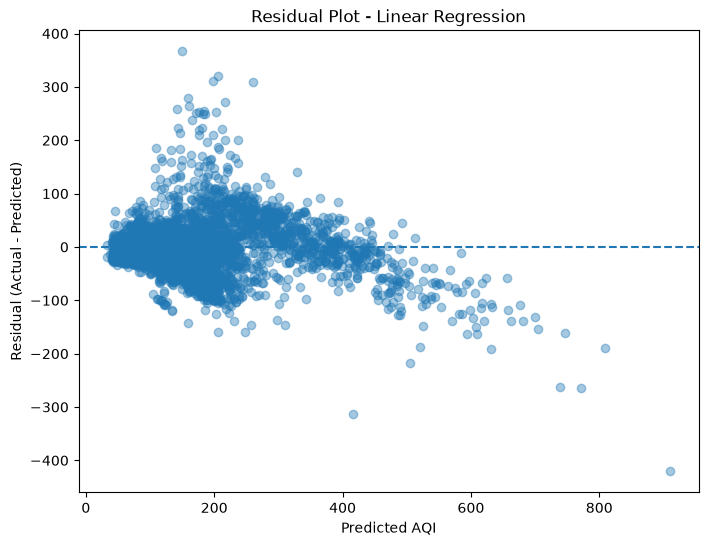

In [181]:
#Plotting Erros 
errors = y_test-sy_y_pred
plt.figure(figsize=(8, 6))

plt.scatter(sy_y_pred, errors, alpha=0.4)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted AQI")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot - Linear Regression")

plt.show()

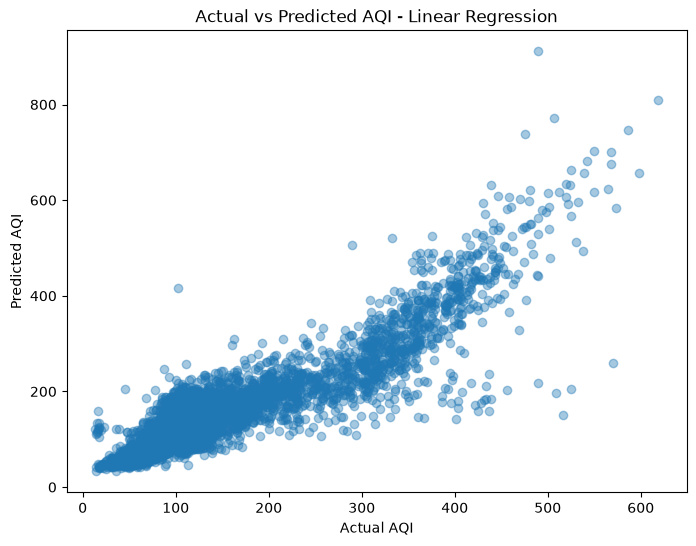

In [182]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, sy_y_pred, alpha=0.4)
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI - Linear Regression")

plt.show()

# Now we will move to a more complex model for better metrics value

In [183]:
from sklearn.tree import DecisionTreeRegressor 
model = DecisionTreeRegressor(max_depth=5)
model.fit(X_train, y_train)
model.predict(X_test)

array([72.44923747, 72.44923747, 72.44923747, ..., 72.44923747,
       72.44923747, 72.44923747], shape=(4970,))

In [198]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_model.predict(X_test)

array([48.56, 48.86, 45.12, ..., 69.32, 59.21, 66.  ], shape=(4970,))

In [200]:

#Checking the errors on RF
sk_rf_mae = mean_absolute_error(y_test, rf_pred)
sk_rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
sk_rf_r2 = r2_score(y_test, rf_pred)

print("MAE:", sk_rf_mae)
print("RMSE:", sk_rf_rmse)
print("R²:", sk_rf_r2)

#Here Random Forest can capturing some non linear relationship which Linear Regression could'nt,
#That's why the metrics from Random Forest model are better than LR.

MAE: 27.35426325765331
RMSE: 41.79694224242423
R²: 0.8486263320163548


# Decision Tree from scratch

In [185]:
class Node:
    def __init__(self, feature=None,threshold=None,left=None,right=None,prediction=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.prediction = prediction

class syDecisionTreeRegressor:

    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y)
        self.root = self.build_me_a_tree(X, y)
        return self

    def predict(self, X):
        X = np.array(X)
        predictions = []
        for x in X:
            predictions.append(self.predict_one(x, self.root))
        return np.array(predictions)

    def build_me_a_tree(self, X, y, depth=0):
        if depth>=self.max_depth or len(y)< self.min_samples_split:
            prediction =np.mean(y)
            return Node(prediction=prediction)

        feature, threshold = self.find_best_split(X, y)

        if feature is None:
            prediction = np.mean(y)
            return Node(prediction=prediction)

        left_mask = X[:, feature] <= threshold
        right_mask = X[:, feature] > threshold

        X_left = X[left_mask]
        X_right = X[right_mask]
        y_left = y[left_mask]
        y_right = y[right_mask]

        left_node = self.build_me_a_tree(X_left, y_left, depth + 1)
        right_node = self.build_me_a_tree(X_right, y_right, depth + 1)

        return Node(feature=feature, threshold=threshold, left=left_node, right=right_node)

    def find_best_split(self, X, y):
        best_mse = float("inf")
        best_feature = None
        best_threshold = None

        for i in range(X.shape[1]):
            values = np.unique(X[:, i])
            thresholds = (values[:-1] + values[1:])/2
            #This part is not optimized by me. For now I am goining
            for threshold in thresholds:
                left = X[:, i] <= threshold
                right = X[:, i] > threshold

                y_left = y[left]
                y_right = y[right]

                if len(y_left) == 0 or len(y_right) == 0:
                    continue

                mse_left = self.calculate_mse(y_left)
                mse_right = self.calculate_mse(y_right)

                weighted_mse = (len(y_left)/len(y))*mse_left + (len(y_right)/len(y))*mse_right

                if weighted_mse < best_mse:
                    best_mse = weighted_mse
                    best_feature = i
                    best_threshold = threshold

        return best_feature, best_threshold

    def calculate_mse(self, y):
        mean = np.mean(y)
        return np.mean((y-mean)**2)

    def predict_one(self, x, node):
        if node.prediction is not None:
            return node.prediction

        if x[node.feature] <= node.threshold:
            return self.predict_one(x, node.left)
        else:
            return self.predict_one(x, node.right)


In [ ]:
sy_tree = syDecisionTreeRegressor(max_depth=5)
sy_tree.fit(X_train, y_train)
sy_dt_pred= sy_tree.predict(X_test)
sy_tree.predict(X_test)

array([72.44923747, 72.44923747, 72.44923747, ..., 72.44923747,
       72.44923747, 72.44923747], shape=(4970,))

In [203]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
sy_rf_mae = mean_absolute_error(y_test, sy_rf_pred)
sy_rf_rmse = root_mean_squared_error(y_test, sy_rf_pred)
sy_rf_r2 = r2_score(y_test, sy_rf_pred)
print("MAE:", sy_rf_mae)
print("RMSE:", sy_rf_rmse)
print("R2:", sy_rf_r2)

MAE: 25.408952267006505
RMSE: 37.91790650526919
R2: 0.8754195155848975


# Comparing output of my Decision Tree Implementation with sklearn's DecisionTreeRegression

In [187]:
from sklearn.tree import DecisionTreeRegressor as SklearnTree
import numpy as np

# My Decision Tree
my_tree = syDecisionTreeRegressor(max_depth=5)
my_tree.fit(X_train, y_train)
my_pred = my_tree.predict(X_test)

# Sklearn Decision Tree
sk_tree = SklearnTree(max_depth=5)
sk_tree.fit(X_train, y_train)
sk_pred = sk_tree.predict(X_test)

print("My predictions:", my_pred[:10])
print("Sklearn predictions:", sk_pred[:10])

print("\nUnique predictions:")
print("My tree:", len(np.unique(my_pred)))
print("Sklearn:", len(np.unique(sk_pred)))

print("\nMy tree root:")
print("Feature:", my_tree.root.feature)
print("Threshold:", my_tree.root.threshold)
print("Prediction:", my_tree.root.prediction)

My predictions: [72.44923747 72.44923747 72.44923747 72.44923747 72.44923747 72.44923747
 72.44923747 72.44923747 72.44923747 72.44923747]
Sklearn predictions: [72.44923747 72.44923747 72.44923747 72.44923747 72.44923747 72.44923747
 72.44923747 72.44923747 72.44923747 72.44923747]

Unique predictions:
My tree: 13
Sklearn: 13

My tree root:
Feature: 3
Threshold: 14.555
Prediction: None


In [188]:
print("Predictions exactly equal:", np.allclose(my_pred, sk_pred))

print("Maximum prediction difference:",np.max(np.abs(my_pred - sk_pred)))

Predictions exactly equal: True
Maximum prediction difference: 0.0


# Random Forest from scratch using my DecisionTree implementation

In [189]:
#Random Forest from scratch 
import numpy as np
class syRandomForestRegressor:

    def __init__(self, n_trees=10, max_depth=5):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.trees = []
    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y)
        self.trees = []
        for i in range(self.n_trees):
            ids = np.random.choice(len(X), len(X), replace=True)
            X_new = X[ids]
            y_new = y[ids]
            tree = syDecisionTreeRegressor(max_depth=self.max_depth)
            tree.fit(X_new, y_new)
            self.trees.append(tree)
        return self
    def predict(self, X):
        results = []
        for tree in self.trees:
            pred = tree.predict(X)
            results.append(pred)
        final = np.mean(results, axis=0)
        return final

In [192]:
myrf = syRandomForestRegressor(n_trees=10)
myrf.fit(X_train,y_train)
myrf.predict(X_test)

array([70.54981257, 70.54981257, 70.54981257, ..., 70.54981257,
       70.54981257, 70.54981257], shape=(4970,))

In [196]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=model_features
).sort_values(ascending=False)

print(importance)
#CO and PM2.5 are the most influential features for AQI prediction, while NO2, SO2, and O3 contributed comparatively less.

CO       0.487641
PM2.5    0.425685
NO2      0.030844
SO2      0.029904
O3       0.025926
dtype: float64


In [ ]:
#XGBOOST 
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = (mean_squared_error(y_test, xgb_pred))**0.5
xgb_r2 = r2_score(y_test, xgb_pred)

print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)
print("R²:", xgb_r2)

MAE: 27.393490167690715
RMSE: 41.18959685733703
R²: 0.8529935483069145


In [ ]:
#Matrix multiplication
# a = [[2,1,3],[0,2,1],[1,2,3]]
# b = [[1,2,4],[1,3,2],[4,2,5]] 
# n = len(a)
# c=[[0]*n for _ in range(n)]
# for i in range(n):
#    for j in range(n):
#       for k in range(n):
#          c[i][j] += b[i][k]*a[k][j]
# print(c)

In [ ]:
# import numpy as np
# class LinearRegression:
#     def __init__(self):
#         self.weights= None
#         self.intercept_ = None
#     def fit(self,X,y):
#         npX= np.array(X)
#         npX = np.c_[np.ones(npX.shape[0]), npX]
#         npy=np.array(y)
#         # self.weights= np.linalg.inv((npX.T@ npX)) @ npX.T @ npy
#         # self.intercept_= np.mean(npy-  npX@self.weights)
#         # mixed = np.linalg.inv((npX.T@ npX)) @ npX.T @ npy
#         mixed = np.linalg.pinv((npX)) @ npy

#         self.intercept_=mixed[0]
#         self.weights=mixed[1:]
#         return self.weights, self.intercept_

    
#     def predict(self,X):
#         npX= np.array(X)
#         return npX @ self.weights +self.intercept_
        
# x = LinearRegression()
# x.fit([[2,1,3],[0,2,1],[1,2,3]],[1,2,3])

# print("Intercept:",x.intercept_)
# print("weights:",x.weights)
# x.predict([[1,2,4],[1,3,2],[4,2,5]])

Intercept: -0.6666666666666679
weights: [-1.22222222  0.77777778  1.11111111]


array([4.11111111, 2.66666667, 1.55555556])

In [ ]:
# from sklearn.linear_model import LinearRegression
# X = [[2,1,3],[0,2,1],[1,2,3]]
# y = [1,2,3]
# model = LinearRegression()
# model.fit(X, y)
# intercept = model.intercept_
# weights = model.coef_
# print("Intercept (Bias):", intercept)
# print("Weights (Slopes):", weights)
# model.predict([[1,2,4],[1,3,2],[4,2,5]])


Intercept (Bias): -1.3333333333333335
Weights (Slopes): [-0.77777778  1.22222222  0.88888889]


array([3.88888889, 3.33333333, 2.44444444])